--- Closest Pair of Points Interactive Solver ---
Enter number of points (N): 5

--- OUTPUT RESULTS ---
239.749795 (-443.7038, 26.3403) (-279.6038, -148.4486)
239.749795 (-443.7038, 26.3403) (-279.6038, -148.4486)
Execution Time: Brute-Force = 0.0205 ms | Divide-and-Conquer = 0.0298 ms

Opening graph visualization window...


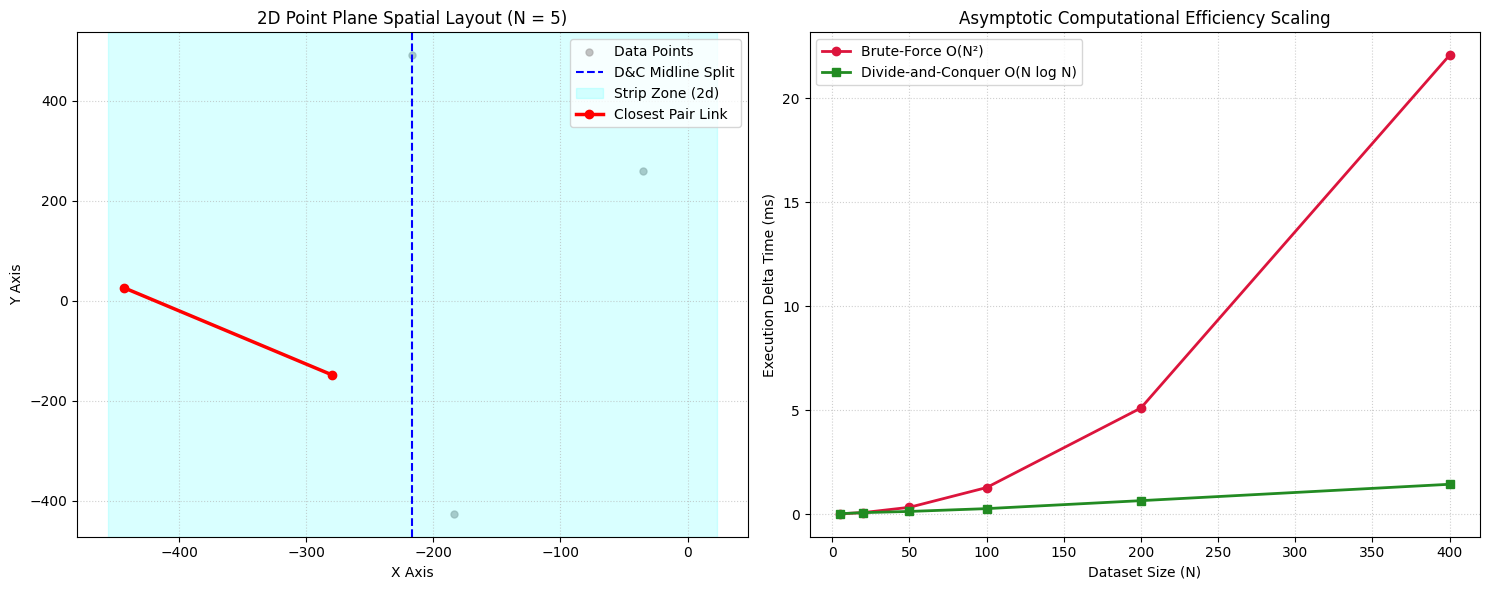

In [6]:
import math
import random
import time
import matplotlib.pyplot as plt

# ==========================================
# 1. CORE ALGORITHMS WITH CORNER CASES
# ==========================================

def distance(p1, p2):
    """Calculates the Euclidean distance between two points."""
    return math.sqrt((p1[0] - p2[0])**2 + (p1[1] - p2[1])**2)

def brute_force(points):
    """O(N^2) exhaustive matching solution."""
    n = len(points)
    if n < 2:
        return float('inf'), None
    min_d = float('inf')
    closest_pair = None
    for i in range(n):
        for j in range(i + 1, n):
            d = distance(points[i], points[j])
            if d < min_d:
                min_d = d
                closest_pair = (points[i], points[j])
    return min_d, closest_pair

def closest_pair_dc(points):
    """O(N log N) recursive divide and conquer solution with visual metadata capture."""
    n = len(points)
    if n < 2:
        return float('inf'), None

    points_x = sorted(points, key=lambda p: p[0])
    points_y = sorted(points, key=lambda p: p[1])

    # Track the final top-level split context for the visualization
    visual_data = {"mid_x": None, "strip_d": None}

    def closest_util(Px, Py, is_top_level=False):
        m = len(Px)
        if m <= 3:
            return brute_force(Px)

        mid = m // 2
        mid_point = Px[mid]
        mid_x = mid_point[0]

        Px_left = Px[:mid]
        Px_right = Px[mid:]

        Py_left = []
        Py_right = []
        left_set = set(Px_left)
        for p in Py:
            if p in left_set:
                Py_left.append(p)
                left_set.remove(p)
            else:
                Py_right.append(p)

        d_left, pair_left = closest_util(Px_left, Py_left)
        d_right, pair_right = closest_util(Px_right, Py_right)

        if d_left < d_right:
            d = d_left
            min_pair = pair_left
        else:
            d = d_right
            min_pair = pair_right

        strip = [p for p in Py if abs(p[0] - mid_x) < d]

        for i in range(len(strip)):
            for j in range(i + 1, len(strip)):
                if (strip[j][1] - strip[i][1]) >= d:
                    break
                dist = distance(strip[i], strip[j])
                if dist < d:
                    d = dist
                    min_pair = (strip[i], strip[j])

        if is_top_level:
            visual_data["mid_x"] = mid_x
            visual_data["strip_d"] = d

        return d, min_pair

    d, pair = closest_util(points_x, points_y, is_top_level=True)
    return d, pair, visual_data

# ==========================================
# 2. INPUT PROCESSING & FORMATTED OUTPUT
# ==========================================

def format_point(p):
    """Formats a coordinate tuple (x, y) into a clean string without tuple errors."""
    return f"({p[0]:.4f}, {p[1]:.4f})"

def main():
    print("--- Closest Pair of Points Interactive Solver ---")
    try:
        # Step 1: Input N from standard terminal prompt
        N = int(input("Enter number of points (N): ").strip())

        if N < 2:
            print("Error: N must be at least 2 to compute pairs.")
            return

        # Step 2: Randomly generate N coordinate points
        points = [(random.uniform(-500.0, 500.0), random.uniform(-500.0, 500.0)) for _ in range(N)]

        # Step 3: Run Brute-Force Algorithm
        start_bf = time.perf_counter()
        bf_dist, bf_pair = brute_force(points)
        end_bf = time.perf_counter()
        bf_time_ms = (end_bf - start_bf) * 1000

        # Step 4: Run Divide-and-Conquer Algorithm
        start_dc = time.perf_counter()
        dc_dist, dc_pair, visual_data = closest_pair_dc(points)
        end_dc = time.perf_counter()
        dc_time_ms = (end_dc - start_dc) * 1000

        # --- STANDARD TEXT OUTPUTS ---
        print("\n--- OUTPUT RESULTS ---")
        print(f"{bf_dist:.6f} {format_point(bf_pair[0])} {format_point(bf_pair[1])}")
        print(f"{dc_dist:.6f} {format_point(dc_pair[0])} {format_point(dc_pair[1])}")
        print(f"Execution Time: Brute-Force = {bf_time_ms:.4f} ms | Divide-and-Conquer = {dc_time_ms:.4f} ms")

        # ==========================================
        # 3. INTERACTIVE VISUALIZATION SUBPLOTS
        # ==========================================
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

        # --- PLOT 1: Point Spatial Plane Map ---
        x_coords = [p[0] for p in points]
        y_coords = [p[1] for p in points]
        ax1.scatter(x_coords, y_coords, color='darkgray', s=25, alpha=0.7, label='Data Points')

        # Draw D&C dividing line and wide strip region zone
        if visual_data["mid_x"] is not None:
            mx = visual_data["mid_x"]
            sd = visual_data["strip_d"]
            ax1.axvline(x=mx, color='blue', linestyle='--', linewidth=1.5, label='D&C Midline Split')
            ax1.axvspan(mx - sd, mx + sd, color='cyan', alpha=0.15, label='Strip Zone (2d)')

        # Draw and link the target matching pair coordinates
        if dc_pair:
            p1, p2 = dc_pair[0], dc_pair[1]
            ax1.plot([p1[0], p2[0]], [p1[1], p2[1]], color='red', linestyle='-', linewidth=2.5, marker='o', label='Closest Pair Link')

        ax1.set_title(f"2D Point Plane Spatial Layout (N = {N})")
        ax1.set_xlabel("X Axis")
        ax1.set_ylabel("Y Axis")
        ax1.legend(loc="upper right")
        ax1.grid(True, linestyle=':', alpha=0.6)

        # --- PLOT 2: Runtime Growth Trends Curve ---
        # Generate empirical test step array size increments dynamically based on user N sizes
        test_sizes = [5, 20, 50, 100, 200, 400]
        if N > 400 and N <= 1500:
            test_sizes.append(N)

        bf_times = []
        dc_times = []

        for size in test_sizes:
            test_pts = [(random.uniform(-500.0, 500.0), random.uniform(-500.0, 500.0)) for _ in range(size)]

            t_start = time.perf_counter()
            brute_force(test_pts)
            bf_times.append((time.perf_counter() - t_start) * 1000)

            t_start = time.perf_counter()
            closest_pair_dc(test_pts)
            dc_times.append((time.perf_counter() - t_start) * 1000)

        ax2.plot(test_sizes, bf_times, label='Brute-Force O(N²)', color='crimson', marker='o', linewidth=2)
        ax2.plot(test_sizes, dc_times, label='Divide-and-Conquer O(N log N)', color='forestgreen', marker='s', linewidth=2)
        ax2.set_xlabel('Dataset Size (N)')
        ax2.set_ylabel('Execution Delta Time (ms)')
        ax2.set_title('Asymptotic Computational Efficiency Scaling')
        ax2.legend(loc="upper left")
        ax2.grid(True, linestyle=':', alpha=0.6)

        # Present visual interface window to the screen
        plt.tight_layout()
        print("\nOpening graph visualization window...")
        plt.show()

    except ValueError:
        print("Invalid entry. Please execute again and pass an integer choice.")

if __name__ == "__main__":
    main()


Choose input: 1 = manual conflicts, 2 = random graph: 2
Enter N R: 5 2
Enter edge density from 0 to 1 (e.g. 0.4): 0.5

--- Welsh-Powell Greedy ---
Slots used: 3
Optimality proven: No (greedy is a heuristic)
Running time: 0.000057 seconds
Validation: All constraints satisfied.
Slot 1: 1, 4
Slot 2: 2, 3
Slot 3: 5

--- Exact Backtracking ---
Slots used: 3
Optimality proven: Yes
Running time: 0.000055 seconds
Validation: All constraints satisfied.
Slot 1: 1, 4
Slot 2: 2, 3
Slot 3: 5
CSV timetable saved to: /content/timetable.csv


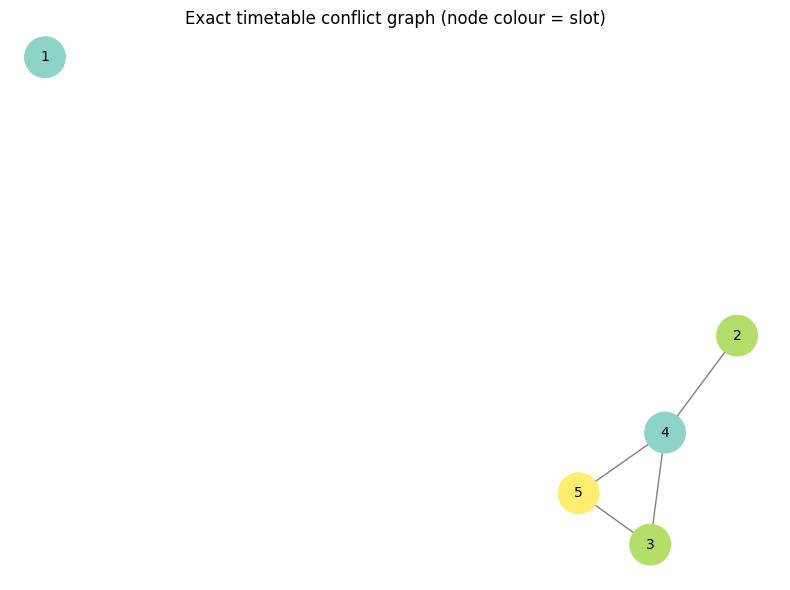

Graph image saved to: /content/conflict_graph.png


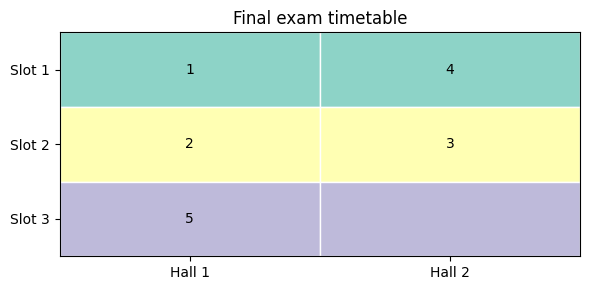

Timetable image saved to: /content/timetable_grid.png


In [18]:
import os
import random
import csv
import time
import argparse
from collections import defaultdict

import networkx as nx
import matplotlib.pyplot as plt


def read_manual_graph():
    """Read N, M, R followed by M conflicting course pairs."""
    N, M, R = map(int, input("Enter N M R: ").split())
    graph = nx.Graph()
    graph.add_nodes_from(range(1, N + 1))

    print(f"Enter {M} conflict pairs (u v), one pair per line:")
    for _ in range(M):
        u, v = map(int, input().split())
        if not (1 <= u <= N and 1 <= v <= N):
            raise ValueError("Course IDs must be between 1 and N.")
        if u == v:
            raise ValueError("A course cannot conflict with itself.")
        graph.add_edge(u, v)

    return graph, R


def generate_random_graph():
    """Read N, R and edge density, then generate a random conflict graph."""
    N, R = map(int, input("Enter N R: ").split())
    density = float(input("Enter edge density from 0 to 1 (e.g. 0.4): "))
    if not 0 <= density <= 1:
        raise ValueError("Edge density must be between 0 and 1.")
    graph = nx.gnp_random_graph(N, density, seed=None)
    # Convert node labels from 0..N-1 to 1..N.
    graph = nx.relabel_nodes(graph, {v: v + 1 for v in graph.nodes()})
    return graph, R


def is_valid_slot(graph, assignment, course, slot, R):
    """Check conflict constraints and the maximum number of exams per slot."""
    if sum(1 for s in assignment.values() if s == slot) >= R:
        return False
    for neighbor in graph.neighbors(course):
        if assignment.get(neighbor) == slot:
            return False
    return True


def welsh_powell(graph, R):
    """Greedy Welsh-Powell ordering, also respecting the hall limit R."""
    if R < 1 and graph.number_of_nodes() > 0:
        raise ValueError("R must be at least 1.")
    order = sorted(graph.nodes(), key=lambda v: graph.degree(v), reverse=True)
    assignment = {}

    for course in order:
        slot = 1
        while not is_valid_slot(graph, assignment, course, slot, R):
            slot += 1
        assignment[course] = slot

    return assignment, max(assignment.values(), default=0)


def exact_backtracking(graph, R, time_limit=10.0):
    """
    Find a minimum-slot timetable by trying slot counts from a lower bound upward.
    Uses DSatur-style vertex selection during backtracking.
    Returns (assignment, slots, proven_optimal, elapsed_seconds).
    A timeout means optimality has not been proven.
    """
    start = time.perf_counter()
    nodes = list(graph.nodes())
    N = len(nodes)

    if N == 0:
        return {}, 0, True, time.perf_counter() - start
    if R < 1:
        raise ValueError("R must be at least 1 when courses exist.")

    # Each slot holds at most R exams, so this is a valid lower bound.
    lower_bound = (N + R - 1) // R
    # A clique also needs different slots; compute a simple lower bound.
    try:
        clique_bound = nx.graph_clique_number(graph)
        lower_bound = max(lower_bound, clique_bound)
    except Exception:
        pass

    timed_out = False

    def solve_with_k(k):
        nonlocal timed_out
        assignment = {}
        slot_counts = [0] * (k + 1)

        def choose_vertex():
            unassigned = [v for v in nodes if v not in assignment]
            # DSatur: most distinct neighbour colours, then degree.
            return max(
                unassigned,
                key=lambda v: (
                    len({assignment[u] for u in graph.neighbors(v)
                         if u in assignment}),
                    graph.degree(v)
                )
            ) if unassigned else None

        def search():
            nonlocal timed_out
            if time.perf_counter() - start > time_limit:
                timed_out = True
                return False
            if len(assignment) == N:
                return True

            v = choose_vertex()
            forbidden = {
                assignment[u] for u in graph.neighbors(v)
                if u in assignment
            }

            # Try existing colours first, then one new colour to avoid
            # equivalent permutations of colour labels.
            used_slots = set(assignment.values())
            candidates = sorted(used_slots)
            if len(used_slots) < k:
                candidates.append(max(used_slots, default=0) + 1)

            for slot in candidates:
                if slot > k or slot in forbidden or slot_counts[slot] >= R:
                    continue
                assignment[v] = slot
                slot_counts[slot] += 1
                if search():
                    return True
                slot_counts[slot] -= 1
                del assignment[v]
                if timed_out:
                    return False
            return False

        if search():
            return assignment.copy()
        return None

    for k in range(lower_bound, N + 1):
        result = solve_with_k(k)
        if result is not None:
            return result, k, True, time.perf_counter() - start
        if timed_out:
            # Return a valid greedy solution but clearly mark it unproven.
            fallback, fallback_slots = welsh_powell(graph, R)
            return fallback, fallback_slots, False, time.perf_counter() - start

    # Should not occur for R >= 1; one course per slot is always valid.
    fallback, fallback_slots = welsh_powell(graph, R)
    return fallback, fallback_slots, False, time.perf_counter() - start


def slots_from_assignment(assignment):
    slots = defaultdict(list)
    for course, slot in assignment.items():
        slots[slot].append(course)
    return dict(sorted((slot, sorted(courses)) for slot, courses in slots.items()))


def validate_timetable(graph, assignment, R):
    for u, v in graph.edges():
        if assignment.get(u) == assignment.get(v):
            return False, f"Conflict: courses {u} and {v} share a slot."
    slots = slots_from_assignment(assignment)
    for slot, courses in slots.items():
        if len(courses) > R:
            return False, f"Slot {slot} exceeds the limit R={R}."
    if len(assignment) != graph.number_of_nodes():
        return False, "Some courses were not assigned."
    return True, "All constraints satisfied."


def save_csv(assignment, filename="timetable.csv"):
    slots = slots_from_assignment(assignment)
    max_halls = max((len(courses) for courses in slots.values()), default=0)
    with open(filename, "w", newline="", encoding="utf-8") as file:
        writer = csv.writer(file)
        writer.writerow(["Slot"] + [f"Hall {i}" for i in range(1, max_halls + 1)])
        for slot, courses in slots.items():
            row = [slot] + courses + [""] * (max_halls - len(courses))
            writer.writerow(row)
    print(f"CSV timetable saved to: {os.path.abspath(filename)}")


def draw_graph(graph, assignment, title, filename):
    pos = nx.spring_layout(graph, seed=7)
    colors = [assignment[v] for v in graph.nodes()]
    plt.figure(figsize=(8, 6))
    nx.draw_networkx(
        graph, pos, node_color=colors, cmap=plt.cm.Set3,
        with_labels=True, node_size=850, font_size=10,
        edge_color="gray"
    )
    plt.title(title + " (node colour = slot)")
    plt.axis("off")
    plt.tight_layout()
    plt.savefig(filename, dpi=150)
    plt.show()
    print(f"Graph image saved to: {os.path.abspath(filename)}")


def draw_timetable(assignment, title, filename):
    slots = slots_from_assignment(assignment)
    if not slots:
        print("No courses to draw.")
        return
    max_halls = max(len(courses) for courses in slots.values())
    slot_ids = list(slots.keys())
    fig, ax = plt.subplots(figsize=(max(6, max_halls * 1.6), max(3, len(slot_ids) * 0.8)))
    for row, slot in enumerate(slot_ids):
        for col in range(max_halls):
            ax.add_patch(plt.Rectangle(
                (col, row), 1, 1,
                facecolor=plt.cm.Set3((slot - 1) % 12 / 12),
                edgecolor="white"
            ))
            label = str(slots[slot][col]) if col < len(slots[slot]) else ""
            ax.text(col + 0.5, row + 0.5, label, ha="center", va="center")
    ax.set_xlim(0, max_halls)
    ax.set_ylim(0, len(slot_ids))
    ax.set_xticks([i + 0.5 for i in range(max_halls)])
    ax.set_xticklabels([f"Hall {i+1}" for i in range(max_halls)])
    ax.set_yticks([i + 0.5 for i in range(len(slot_ids))])
    ax.set_yticklabels([f"Slot {s}" for s in slot_ids])
    ax.invert_yaxis()
    ax.set_title(title)
    ax.set_aspect("auto")
    plt.tight_layout()
    plt.savefig(filename, dpi=150)
    plt.show()
    print(f"Timetable image saved to: {os.path.abspath(filename)}")


def compare_algorithms(max_n=30, density=0.25, R=3, exact_time_limit=2.0):
    """Run both algorithms for increasing graph sizes and draw comparison charts."""
    sizes = list(range(5, max_n + 1, 5))
    greedy_slots, exact_slots = [], []
    greedy_times, exact_times = [], []

    for n in sizes:
        graph = nx.gnp_random_graph(n, density, seed=100 + n)
        graph = nx.relabel_nodes(graph, {v: v + 1 for v in graph.nodes()})

        start = time.perf_counter()
        _, g_count = welsh_powell(graph, R)
        greedy_times.append(time.perf_counter() - start)
        greedy_slots.append(g_count)

        _, e_count, optimal, elapsed = exact_backtracking(
            graph, R, time_limit=exact_time_limit
        )
        exact_times.append(elapsed)
        exact_slots.append(e_count)
        print(f"N={n:>3}: Greedy={g_count} slots; "
              f"Exact={e_count} slots; optimality proven={optimal}")

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    axes[0].plot(sizes, greedy_slots, marker="o", label="Welsh-Powell")
    axes[0].plot(sizes, exact_slots, marker="s", label="Exact/backtracking result")
    axes[0].set_title("Number of slots vs N")
    axes[0].set_xlabel("Number of courses (N)")
    axes[0].set_ylabel("Slots used")
    axes[0].legend()
    axes[0].grid(True)

    axes[1].plot(sizes, greedy_times, marker="o", label="Welsh-Powell")
    axes[1].plot(sizes, exact_times, marker="s", label="Exact/backtracking")
    axes[1].set_title("Running time vs N")
    axes[1].set_xlabel("Number of courses (N)")
    axes[1].set_ylabel("Seconds")
    axes[1].legend()
    axes[1].grid(True)

    plt.tight_layout()
    plt.savefig("algorithm_comparison.png", dpi=150)
    plt.show()
    print("Comparison chart saved to:", os.path.abspath("algorithm_comparison.png"))


def main():
    parser = argparse.ArgumentParser(description="Exam timetable scheduling using graph colouring")
    parser.add_argument("--mode", choices=["manual", "random"], default=None,
                        help="Input mode; if omitted, you will be asked")
    parser.add_argument("--time-limit", type=float, default=10.0,
                        help="Seconds allowed for exact search")
    parser.add_argument("--compare", action="store_true",
                        help="Also generate algorithm comparison charts")
    parser.add_argument("--max-n", type=int, default=30,
                        help="Largest graph size for comparison")
    parser.add_argument("--density", type=float, default=0.25,
                        help="Edge density for comparison graphs")
    args, _unknown_args = parser.parse_known_args()  # Ignore Jupyter/Colab kernel arguments

    mode = args.mode or input("Choose input: 1 = manual conflicts, 2 = random graph: ").strip()
    if mode in ("1", "manual"):
        graph, R = read_manual_graph()
    elif mode in ("2", "random"):
        graph, R = generate_random_graph()
    else:
        raise ValueError("Choose 1/manual or 2/random.")

    if graph.number_of_nodes() > 0 and R < 1:
        raise ValueError("R must be at least 1.")
    if R > graph.number_of_nodes() and graph.number_of_nodes() > 0:
        print("Note: R exceeds N, so the hall limit will not restrict the schedule.")

    print("\n--- Welsh-Powell Greedy ---")
    start = time.perf_counter()
    greedy_assignment, greedy_count = welsh_powell(graph, R)
    greedy_elapsed = time.perf_counter() - start
    valid, message = validate_timetable(graph, greedy_assignment, R)
    print(f"Slots used: {greedy_count}")
    print("Optimality proven: No (greedy is a heuristic)")
    print(f"Running time: {greedy_elapsed:.6f} seconds")
    print("Validation:", message)
    for slot, courses in slots_from_assignment(greedy_assignment).items():
        print(f"Slot {slot}: {', '.join(map(str, courses))}")

    print("\n--- Exact Backtracking ---")
    exact_assignment, exact_count, optimal, exact_elapsed = exact_backtracking(
        graph, R, time_limit=args.time_limit
    )
    valid, message = validate_timetable(graph, exact_assignment, R)
    print(f"Slots used: {exact_count}")
    print(f"Optimality proven: {'Yes' if optimal else 'No (time limit reached)'}")
    print(f"Running time: {exact_elapsed:.6f} seconds")
    print("Validation:", message)
    for slot, courses in slots_from_assignment(exact_assignment).items():
        print(f"Slot {slot}: {', '.join(map(str, courses))}")

    save_csv(exact_assignment, "timetable.csv")
    draw_graph(graph, exact_assignment, "Exact timetable conflict graph", "conflict_graph.png")
    draw_timetable(exact_assignment, "Final exam timetable", "timetable_grid.png")

    if args.compare:
        compare_algorithms(max_n=args.max_n, density=args.density, R=R)


if __name__ == "__main__":
    main()